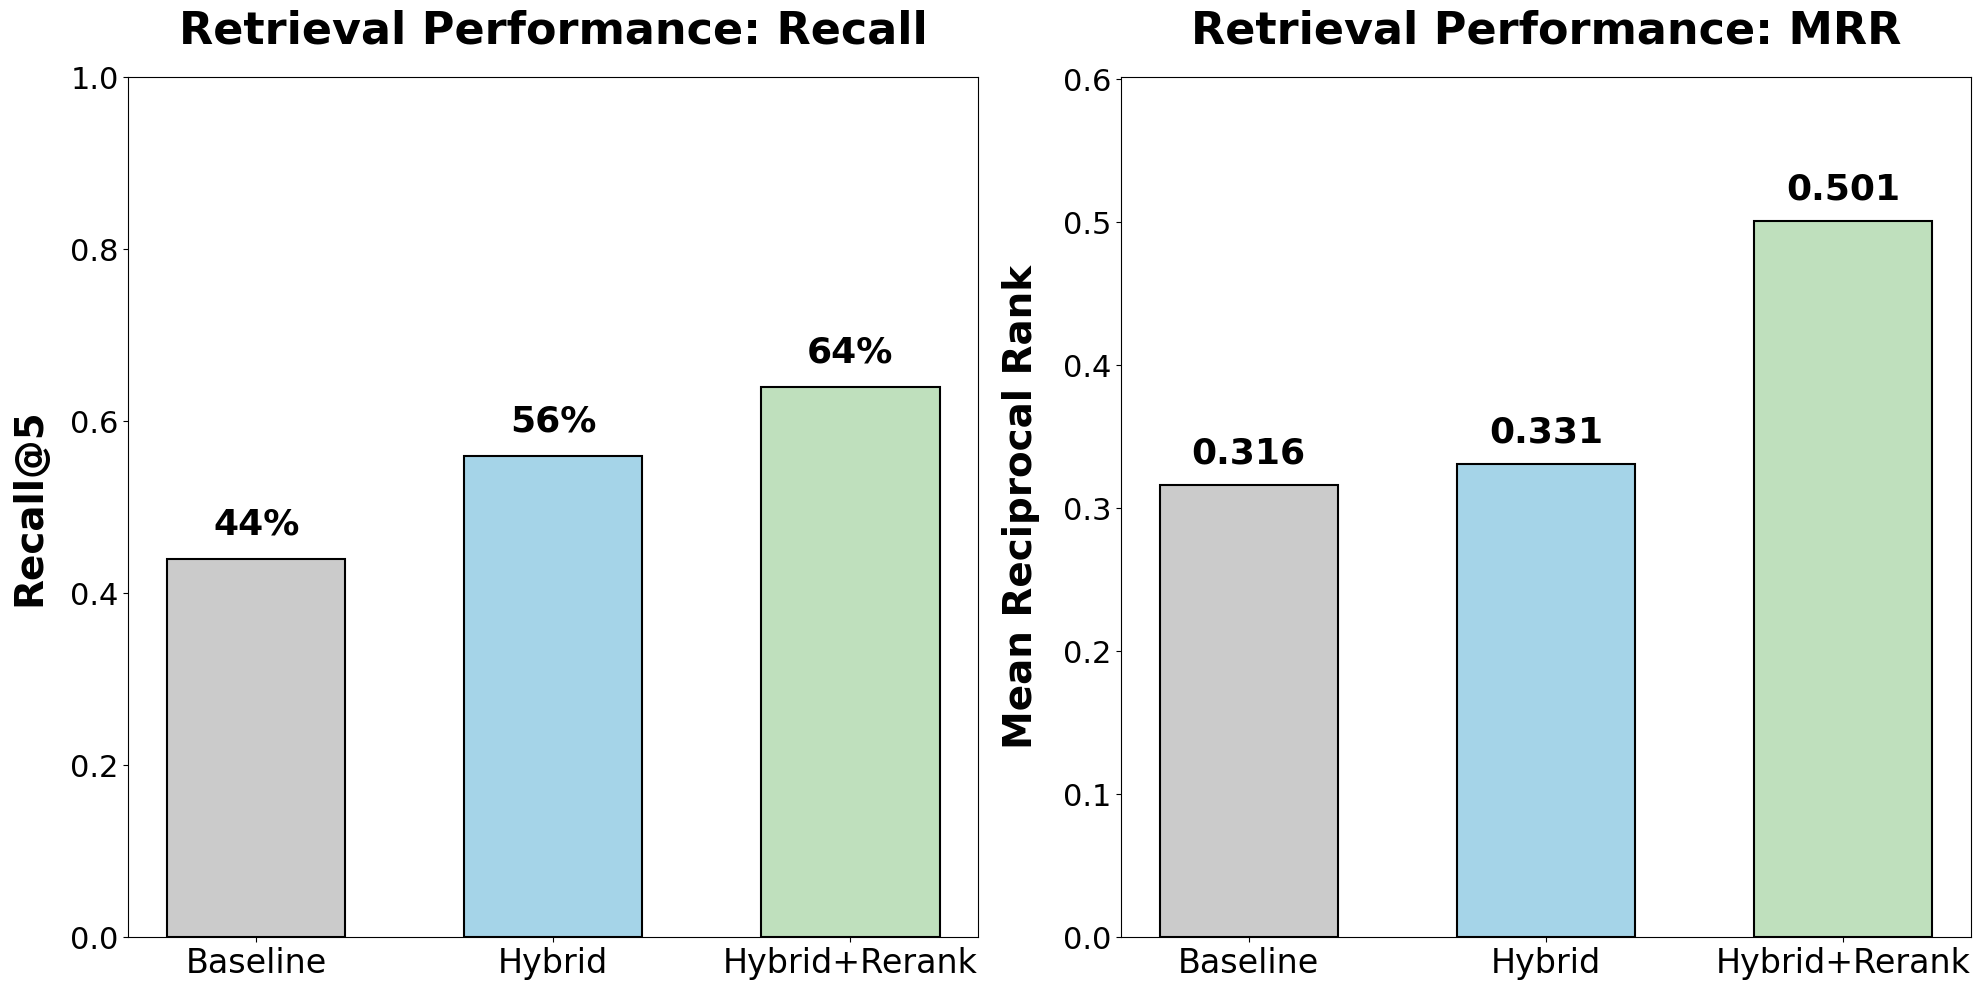

Recall@5 - Baseline: 44%, Hybrid: 56%, Hybrid+Rerank: 64%
MRR - Baseline: 0.316, Hybrid: 0.331, Hybrid+Rerank: 0.501


In [13]:
import json
import matplotlib.pyplot as plt
import numpy as np

# Load the latest evaluation results
with open('retrieval_eval_results.json', 'r') as f:
    data = json.load(f)

# Extract overall summary metrics
summary = data['summary']
baseline_recall = summary['baseline_recall']
hybrid_recall = summary['hybrid_recall']
hybrid_rerank_recall = summary['hybrid_rerank_recall']
baseline_mrr = summary['baseline_mrr']
hybrid_mrr = summary['hybrid_mrr']
hybrid_rerank_mrr = summary['hybrid_rerank_mrr']

# Create plot with two subplots — Recall and MRR
modes = ['Baseline', 'Hybrid', 'Hybrid+Rerank']
recalls = [baseline_recall, hybrid_recall, hybrid_rerank_recall]
mrrs = [baseline_mrr, hybrid_mrr, hybrid_rerank_mrr]
pastel_colors = ['#CBCBCB', '#A5D4E8', '#BFE0BD']  # darker pastels: grey, blue, green

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(20, 10), facecolor='white')
fig.subplots_adjust(left=0.08, right=0.96, top=0.92, bottom=0.08, wspace=0.24)

# Recall chart
bars1 = ax1.bar(modes, recalls, color=pastel_colors, edgecolor='black', linewidth=1.5, width=0.6)
ax1.set_ylabel('Recall@5', fontsize=28, fontweight='bold', labelpad=16)
ax1.set_title('Retrieval Performance: Recall', fontsize=32, fontweight='bold', pad=24)
ax1.set_ylim(0, 1.0)
ax1.tick_params(axis='x', labelsize=24)
ax1.tick_params(axis='y', labelsize=22)

# Add value labels on Recall bars
for bar, recall in zip(bars1, recalls):
    height = bar.get_height()
    ax1.text(bar.get_x() + bar.get_width()/2, height + 0.02, f'{recall:.0%}', 
            ha='center', va='bottom', fontsize=26, fontweight='bold')

# MRR chart
bars2 = ax2.bar(modes, mrrs, color=pastel_colors, edgecolor='black', linewidth=1.5, width=0.6)
ax2.set_ylabel('Mean Reciprocal Rank', fontsize=28, fontweight='bold', labelpad=16)
ax2.set_title('Retrieval Performance: MRR', fontsize=32, fontweight='bold', pad=24)
ax2.set_ylim(0, max(mrrs) * 1.2)
ax2.tick_params(axis='x', labelsize=24)
ax2.tick_params(axis='y', labelsize=22)

# Add value labels on MRR bars
for bar, mrr in zip(bars2, mrrs):
    height = bar.get_height()
    ax2.text(bar.get_x() + bar.get_width()/2, height + max(mrrs)*0.02, f'{mrr:.3f}', 
            ha='center', va='bottom', fontsize=26, fontweight='bold')

plt.tight_layout()
plt.show()

print(f'Recall@5 - Baseline: {baseline_recall:.0%}, Hybrid: {hybrid_recall:.0%}, Hybrid+Rerank: {hybrid_rerank_recall:.0%}')
print(f'MRR - Baseline: {baseline_mrr:.3f}, Hybrid: {hybrid_mrr:.3f}, Hybrid+Rerank: {hybrid_rerank_mrr:.3f}')

/var/folders/9x/k2xh6kxn6dj79y9c4rk64j280000gn/T/ipykernel_1156/915415766.py:87: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax2.set_xticklabels(modes, fontsize=28)


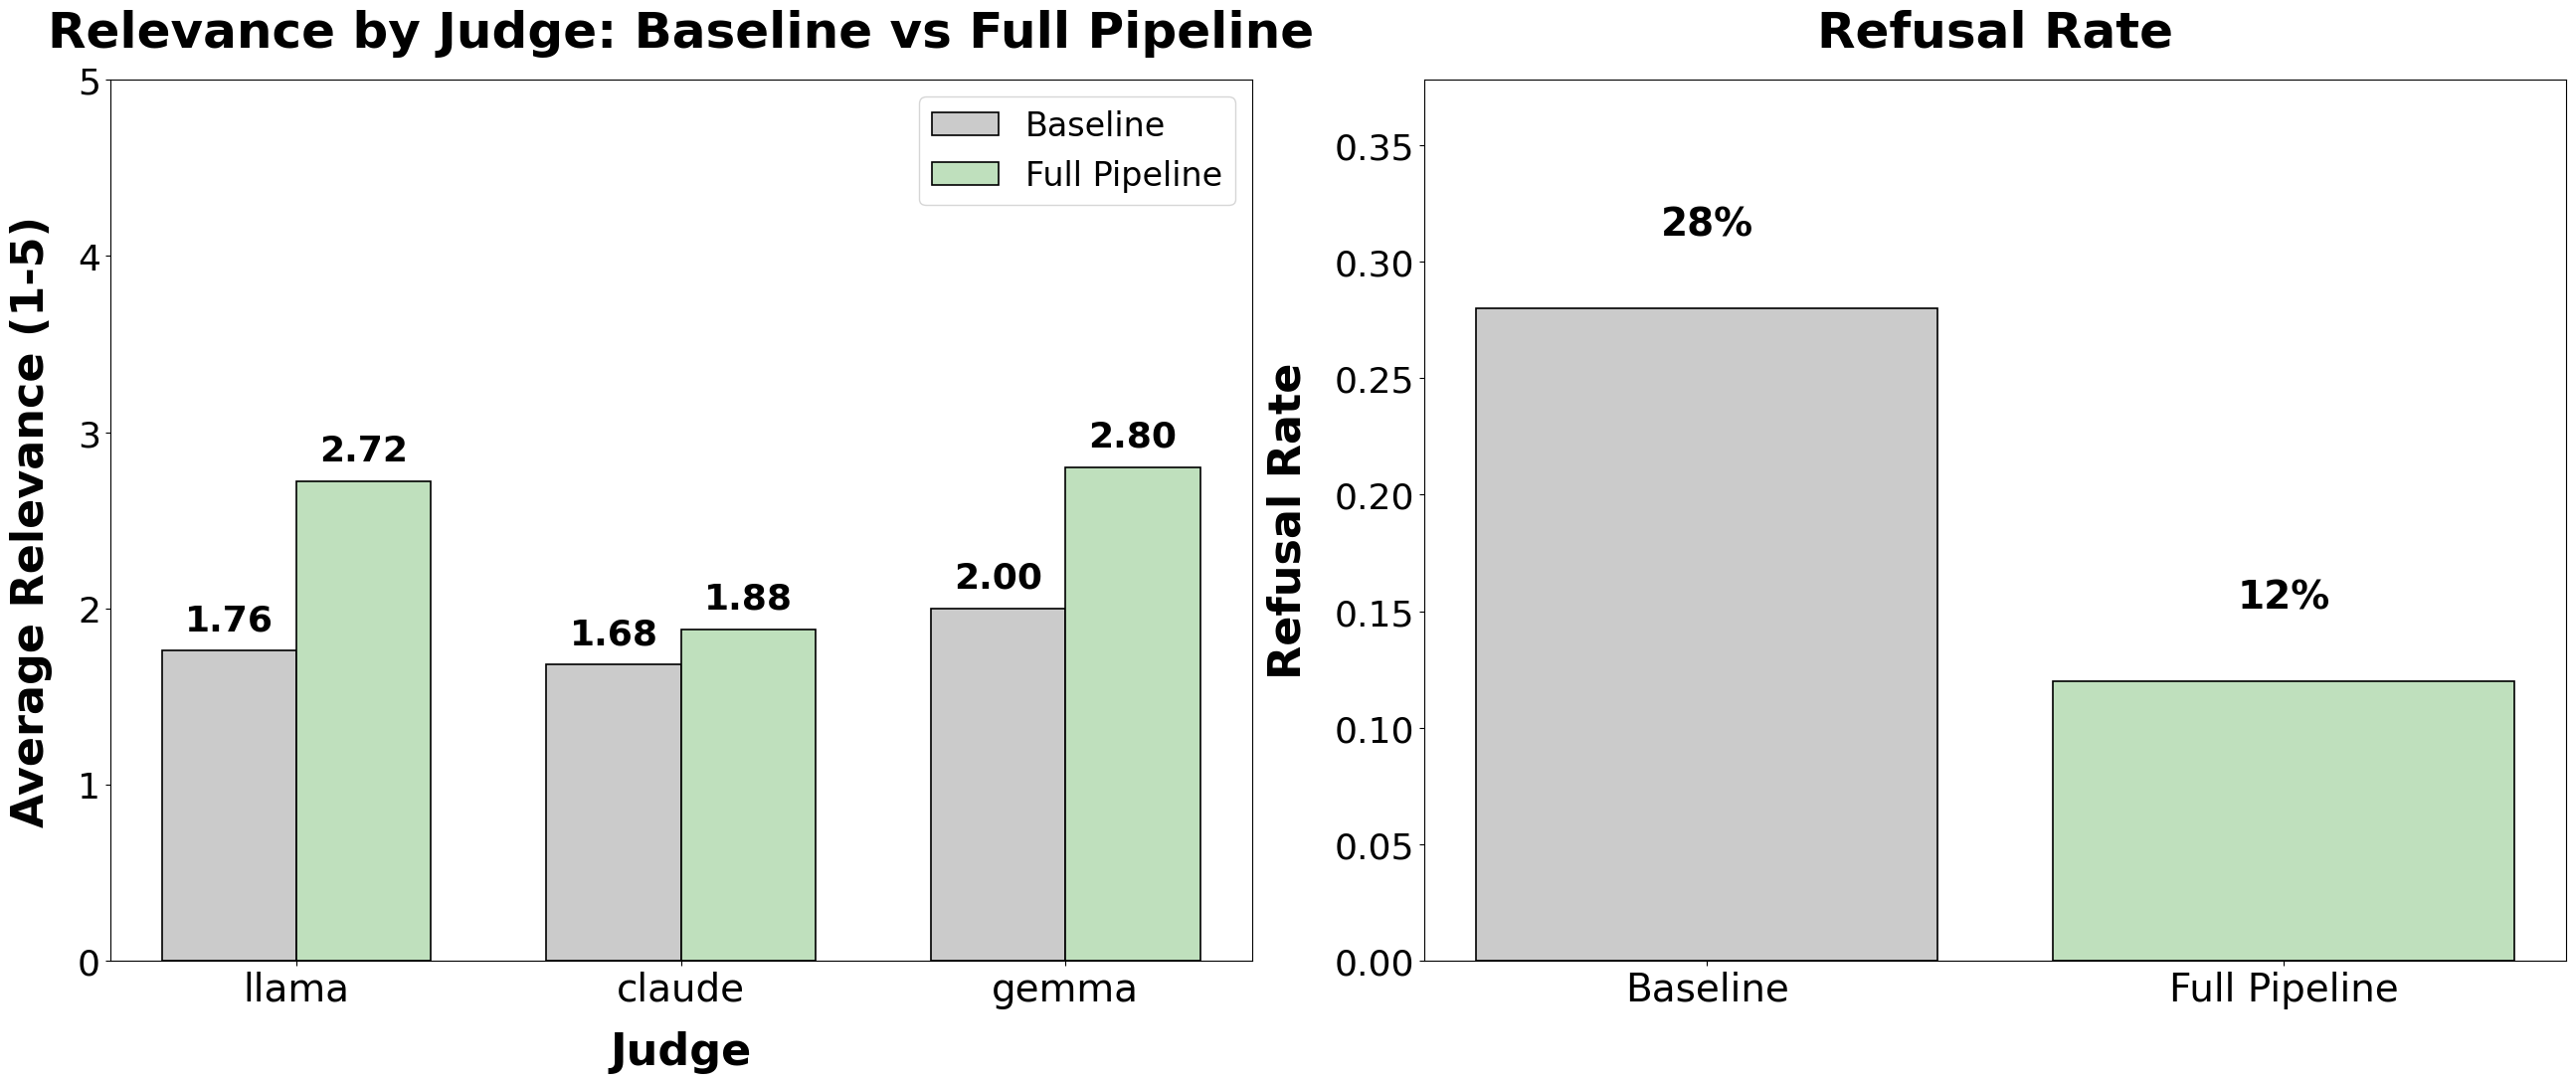

Refusal rate: Baseline 28%, Full 12% (-16% change)
Judges: llama, claude, gemma. Base model is now OpenAI.


In [14]:
import json
import matplotlib.pyplot as plt
import numpy as np

# Load generation evaluation results
with open('generation_eval_results.json', 'r') as f:
    gen_data = json.load(f)

results = gen_data['results']

# Judges
judges = ['llama', 'claude', 'gemma']

# Collect relevance scores per judge
baseline_relevance = {j: [] for j in judges}
full_relevance = {j: [] for j in judges}

# Count refusals based on answer text patterns
refusal_patterns = [
    "can't", "cannot", "cannot find", "not able", "no relevant", "not relevant",
    "don't know", "do not know", "unable", "sorry", "refuse", "cannot answer",
    "don't have", "do not have", "not answer", "not sure"
]

baseline_refusals = 0
full_refusals = 0

for res in results:
    # Baseline relevance
    baseline_judges = res['baseline_judges']
    for j in judges:
        baseline_relevance[j].append(baseline_judges[j]['relevance'])

    # Full relevance
    full_judges = res['full_judges']
    for j in judges:
        full_relevance[j].append(full_judges[j]['relevance'])

    # Refusal detection from answer text
    baseline_text = res.get('baseline_answer', '').lower()
    full_text = res.get('full_answer', '').lower()
    if any(p in baseline_text for p in refusal_patterns):
        baseline_refusals += 1
    if any(p in full_text for p in refusal_patterns):
        full_refusals += 1

# Average relevance per judge
avg_baseline = [np.mean(baseline_relevance[j]) for j in judges]
avg_full = [np.mean(full_relevance[j]) for j in judges]

# Refusal rates
refusal_rates = [baseline_refusals / len(results), full_refusals / len(results)]

# Create subplots with darker pastel colors
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(26, 11), facecolor='white')
fig.subplots_adjust(left=0.08, right=0.96, top=0.92, bottom=0.08, wspace=0.24)

# Darker pastel colors
pastel_grey = '#CBCBCB'
pastel_green = '#BFE0BD'

# Relevance by judge
x = np.arange(len(judges))
width = 0.35

ax1.bar(x - width/2, avg_baseline, width, label='Baseline', color=pastel_grey, edgecolor='black', linewidth=1.2)
ax1.bar(x + width/2, avg_full, width, label='Full Pipeline', color=pastel_green, edgecolor='black', linewidth=1.2)
ax1.set_xlabel('Judge', fontsize=32, fontweight='bold', labelpad=16)
ax1.set_ylabel('Average Relevance (1-5)', fontsize=32, fontweight='bold', labelpad=18)
ax1.set_title('Relevance by Judge: Baseline vs Full Pipeline', fontsize=36, fontweight='bold', pad=24)
ax1.set_xticks(x)
ax1.set_xticklabels(judges, fontsize=28)
ax1.set_ylim(0, 5)
ax1.tick_params(axis='y', labelsize=26)
ax1.legend(fontsize=24)
for i in range(len(judges)):
    ax1.text(x[i] - width/2, avg_baseline[i] + 0.08, f'{avg_baseline[i]:.2f}', ha='center', va='bottom', fontsize=26, fontweight='bold')
    ax1.text(x[i] + width/2, avg_full[i] + 0.08, f'{avg_full[i]:.2f}', ha='center', va='bottom', fontsize=26, fontweight='bold')

# Refusal rate
modes = ['Baseline', 'Full Pipeline']
bar_colors = [pastel_grey, pastel_green]
bars = ax2.bar(modes, refusal_rates, color=bar_colors, edgecolor='black', linewidth=1.2)
ax2.set_title('Refusal Rate', fontsize=36, fontweight='bold', pad=24)
ax2.set_ylabel('Refusal Rate', fontsize=32, fontweight='bold', labelpad=18)
ax2.set_ylim(0, max(refusal_rates) * 1.35 if max(refusal_rates) < 0.75 else 1.0)
ax2.set_xticklabels(modes, fontsize=28)
ax2.tick_params(axis='y', labelsize=26)
for bar, v in zip(bars, refusal_rates):
    ax2.text(bar.get_x() + bar.get_width() / 2, v + 0.028, f'{v:.0%}', ha='center', va='bottom', fontsize=28, fontweight='bold')

plt.tight_layout()
plt.show()

print(f'Refusal rate: Baseline {refusal_rates[0]:.0%}, Full {refusal_rates[1]:.0%} ({(refusal_rates[1] - refusal_rates[0]):+.0%} change)')
print('Judges: llama, claude, gemma. Base model is now OpenAI.')